# LAB 2 – Bài tập thêm, Bài 2: F-measure của các bài tập cơ bản (Trang 32)
F-measure là trung bình điều hòa của Precision và Recall: **F = 2 × Precision × Recall / (Precision + Recall)**. Notebook tự cài đặt ID3, CART (đa nhánh như tài liệu) và Naïve Bayes làm trơn Laplace, áp dụng cho 3 bài cơ bản: *Yêu cầu cơ bản (rủi ro vay tín dụng)*, *Bài 1 – Doanh số đồ chơi*, *Bài 2 – Phân tích cảm xúc*.


In [1]:
HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"


def in_ten():
    print(f"{HO_TEN} - {MSSV}")


in_ten()

Lê Quốc Trung - 6451071082


## 1. Hàm dùng chung (entropy, Gini, xây cây, Naïve Bayes, chỉ số đánh giá)




In [2]:
import math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------- Độ đo ----------
def entropy(nhan):
    n = len(nhan)
    return -sum((k / n) * math.log2(k / n) for k in Counter(nhan).values())


def gini_nut(nhan):
    n = len(nhan)
    return 1 - sum((k / n) ** 2 for k in Counter(nhan).values())


def do_loi_thong_tin(df, thuoc_tinh, cot_nhan):
    """Gain(S, A) = Entropy(S) - sum(|Sv|/|S| * Entropy(Sv))"""
    n = len(df)
    ig = entropy(list(df[cot_nhan]))
    for _, nhom in df.groupby(thuoc_tinh):
        ig -= len(nhom) / n * entropy(list(nhom[cot_nhan]))
    return ig


def gini_phan_nhanh(df, thuoc_tinh, cot_nhan):
    """Gini_A(S) = sum(|Sv|/|S| * Gini(Sv))"""
    n = len(df)
    return sum(len(nhom) / n * gini_nut(list(nhom[cot_nhan])) for _, nhom in df.groupby(thuoc_tinh))


# ---------- Cây quyết định (đa nhánh) ----------
def xay_cay(df, cot_nhan, thuoc_tinh, tieu_chi="entropy", uu_tien="dau"):
    """tieu_chi: 'entropy' (ID3, chọn Gain lớn nhất) hoặc 'gini' (CART, chọn Gini nhỏ nhất).
    uu_tien: khi hòa điểm chọn thuộc tính đứng đầu ('dau') hay cuối ('cuoi') danh sách."""
    nhan = list(df[cot_nhan])
    da_so = Counter(nhan).most_common(1)[0][0]
    if len(set(nhan)) == 1 or not thuoc_tinh:
        return {"la": da_so}
    if tieu_chi == "entropy":
        diem = {a: round(do_loi_thong_tin(df, a, cot_nhan), 9) for a in thuoc_tinh}
        tot = max(diem.values())
    else:
        diem = {a: round(gini_phan_nhanh(df, a, cot_nhan), 9) for a in thuoc_tinh}
        tot = min(diem.values())
    ung_vien = [a for a in thuoc_tinh if diem[a] == tot]
    chon = ung_vien[0] if uu_tien == "dau" else ung_vien[-1]
    con = {gt: xay_cay(nhom, cot_nhan, [a for a in thuoc_tinh if a != chon], tieu_chi, uu_tien)
           for gt, nhom in df.groupby(chon)}
    return {"thuoc_tinh": chon, "con": con, "mac_dinh": da_so}


def du_doan_cay(nut, mau):
    while "la" not in nut:
        gt = mau[nut["thuoc_tinh"]]
        if gt not in nut["con"]:
            return nut["mac_dinh"]
        nut = nut["con"][gt]
    return nut["la"]


def in_cay(nut, muc=0):
    tab = "|   " * muc
    if "la" in nut:
        print(f"{tab}|--- => {nut['la']}")
        return
    for gt, con in nut["con"].items():
        print(f"{tab}|--- [{nut['thuoc_tinh']}] = {gt}")
        in_cay(con, muc + 1)


# ---------- Naïve Bayes + làm trơn Laplace ----------
def huan_luyen_nb(df, cot_nhan):
    lop = df[cot_nhan].value_counts().to_dict()
    tt = [a for a in df.columns if a != cot_nhan]
    return {"n": len(df), "lop": lop, "so_gt": {a: df[a].nunique() for a in tt},
            "dem": {(c, a): df[df[cot_nhan] == c][a].value_counts().to_dict() for c in lop for a in tt}}


def diem_nb(mo_hinh, mau):
    """P(c) * prod P(x_i | c) với Laplace: (đếm + 1) / (tổng + số giá trị khác nhau)."""
    diem = {}
    for c, nc in mo_hinh["lop"].items():
        p = (nc + 1) / (mo_hinh["n"] + len(mo_hinh["lop"]))
        for a, gt in mau.items():
            p *= (mo_hinh["dem"][(c, a)].get(gt, 0) + 1) / (nc + mo_hinh["so_gt"][a])
        diem[c] = p
    return diem


def du_doan_nb(mo_hinh, mau):
    d = diem_nb(mo_hinh, mau)
    return max(d, key=d.get)


# ---------- Ma trận nhầm lẫn, Precision, Recall, F-measure ----------
def ma_tran_nham_lan(thuc_te, du_doan, cac_lop):
    cm = pd.DataFrame(0, index=pd.Index(cac_lop, name="Thực tế"), columns=pd.Index(cac_lop, name="Dự đoán"))
    for t, d in zip(thuc_te, du_doan):
        cm.loc[t, d] += 1
    return cm


def chi_so_lop(cm, lop):
    tp = cm.loc[lop, lop]
    fp = cm[lop].sum() - tp
    fn = cm.loc[lop].sum() - tp
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f

## 2. Hàm giải trọn một bài (a → k)
Với mỗi bài: kiểm tra mâu thuẫn → tính Information Gain / Gini ở nút gốc → dựng cây ID3 và CART → dự đoán bằng cây & Naïve Bayes (Laplace) → ma trận nhầm lẫn, Precision, Recall, **F-measure**.

*Quy ước*: bài 2 lớp chọn một lớp làm **lớp dương** (đồng thời in chỉ số cả hai lớp và F-measure macro để đối chiếu); bài nhiều lớp (cảm xúc) tính theo từng lớp và lấy trung bình **macro**. Khi hòa điểm, ID3 chọn thuộc tính đứng trước, CART chọn thuộc tính đứng sau (khớp với lời giải trong tài liệu).

In [3]:
tong_hop = []   # gom kết quả của mọi bài để so sánh ở mục 6


def giai_bai(ten_bai, df, cot_nhan, test_df, thuc_te, lop_duong=None, mau_moi=None):
    tt = [a for a in df.columns if a != cot_nhan]
    cac_lop = sorted(df[cot_nhan].unique())
    print("=" * 78)
    print(ten_bai)
    print("=" * 78)

    # (a) Mâu thuẫn: các dòng giống hệt thuộc tính nhưng khác nhãn
    so_nhan = df.groupby(tt)[cot_nhan].nunique()
    mau_thuan = so_nhan[so_nhan > 1]
    print(f"[a] Số nhóm dòng mâu thuẫn: {len(mau_thuan)}" + ("  => không có mâu thuẫn" if len(mau_thuan) == 0 else ""))
    if len(mau_thuan):
        display(mau_thuan.to_frame("số nhãn khác nhau"))

    # (b, c) Information Gain & Gini ở nút gốc
    print(f"\n[b,c] Entropy(S) = {entropy(list(df[cot_nhan])):.4f} | Gini(S) = {gini_nut(list(df[cot_nhan])):.4f}")
    bang = pd.DataFrame({
        "Information Gain": {a: do_loi_thong_tin(df, a, cot_nhan) for a in tt},
        "Gini index": {a: gini_phan_nhanh(df, a, cot_nhan) for a in tt}}).round(4)
    display(bang)
    print("=> Gốc ID3 :", bang["Information Gain"].idxmax(), "| Gốc CART:", bang["Gini index"].idxmin())

    cay_id3 = xay_cay(df, cot_nhan, tt, "entropy", "dau")
    cay_cart = xay_cay(df, cot_nhan, tt, "gini", "cuoi")
    print("\nCây ID3:")
    in_cay(cay_id3)
    print("\nCây CART:")
    in_cay(cay_cart)

    # (d, i) Dự đoán
    mo_hinh = huan_luyen_nb(df, cot_nhan)
    kq = test_df.copy()
    kq["ID3"] = [du_doan_cay(cay_id3, r) for _, r in test_df.iterrows()]
    kq["CART"] = [du_doan_cay(cay_cart, r) for _, r in test_df.iterrows()]
    kq["Naive Bayes"] = [du_doan_nb(mo_hinh, r.to_dict()) for _, r in test_df.iterrows()]
    kq["Thực tế"] = thuc_te
    print("\n[d,i] Kết quả dự đoán:")
    display(kq)

    print("Điểm Naïve Bayes (tử số, đã làm trơn Laplace) của từng hồ sơ:")
    for i, (_, r) in enumerate(test_df.iterrows(), 1):
        print(f"  Hồ sơ {i}:", {k: round(v, 5) for k, v in diem_nb(mo_hinh, r.to_dict()).items()})

    # (e, j, k) Ma trận nhầm lẫn + Precision, Recall, F-measure
    for mh in ["ID3", "CART", "Naive Bayes"]:
        cm = ma_tran_nham_lan(thuc_te, kq[mh], cac_lop)
        print(f"\n--- {mh}: ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán) ---")
        display(cm)
        bang_lop = pd.DataFrame([chi_so_lop(cm, l) for l in cac_lop], index=cac_lop,
                                columns=["Precision", "Recall", "F-measure"])
        print("Chỉ số theo từng lớp:")
        display(bang_lop.round(4))
        f_macro = bang_lop["F-measure"].mean()
        if lop_duong is not None:
            p, r, f = chi_so_lop(cm, lop_duong)
            print(f"Lớp dương = '{lop_duong}':  Precision = {p:.4f} | Recall = {r:.4f} | F-measure = {f:.4f}"
                  f"   (F-measure macro hai lớp = {f_macro:.4f})")
        else:
            p, r, f = bang_lop.mean()
            print(f"Trung bình macro:  Precision = {p:.4f} | Recall = {r:.4f} | F-measure = {f:.4f}")
        tong_hop.append({"Bài": ten_bai.split(":")[0], "Mô hình": mh, "Lớp dương": lop_duong or "macro (3 lớp)",
                         "Precision": p, "Recall": r, "F-measure": f, "F-measure macro": f_macro})

    # Dự đoán sản phẩm/mẫu mới (nếu có)
    if mau_moi is not None:
        print("\n[l] Dự đoán mẫu mới:")
        moi = mau_moi.copy()
        moi["ID3"] = [du_doan_cay(cay_id3, r) for _, r in mau_moi.iterrows()]
        moi["CART"] = [du_doan_cay(cay_cart, r) for _, r in mau_moi.iterrows()]
        moi["Naive Bayes"] = [du_doan_nb(mo_hinh, r.to_dict()) for _, r in mau_moi.iterrows()]
        display(moi)

## 3. Yêu cầu cơ bản – Đánh giá rủi ro hồ sơ vay tín dụng

In [4]:
in_ten()
cot = ["Thu nhập", "Nghề nghiệp", "Tình trạng hôn nhân", "Sở hữu nhà", "Nguy cơ"]
du_lieu_vay = pd.DataFrame([
    ["Thấp", "Vận tải", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Vận tải", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Vận tải", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Độc thân", "Rồi", "Rủi ro cao"],
    ["Thấp", "Kinh doanh", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Thấp", "Truyền thông", "Đã kết hôn", "Chưa", "Rủi ro thấp"],
    ["Cao", "Truyền thông", "Độc thân", "Chưa", "Rủi ro thấp"],
    ["Cao", "Vận tải", "Đã kết hôn", "Rồi", "Rủi ro thấp"],
    ["Trung bình", "Truyền thông", "Độc thân", "Chưa", "Rủi ro cao"],
    ["Cao", "Kinh doanh", "Độc thân", "Rồi", "Rủi ro cao"],
], columns=cot)

test_vay = pd.DataFrame([
    ["Trung bình", "Vận tải", "Độc thân", "Rồi"],
    ["Cao", "Truyền thông", "Độc thân", "Rồi"],
    ["Thấp", "Vận tải", "Đã kết hôn", "Rồi"],
], columns=cot[:-1])
thuc_te_vay = ["Rủi ro cao", "Rủi ro thấp", "Rủi ro thấp"]

giai_bai("Yêu cầu cơ bản: Rủi ro vay tín dụng", du_lieu_vay, "Nguy cơ", test_vay, thuc_te_vay, lop_duong="Rủi ro thấp")

Lê Quốc Trung - 6451071082
Yêu cầu cơ bản: Rủi ro vay tín dụng
[a] Số nhóm dòng mâu thuẫn: 0  => không có mâu thuẫn

[b,c] Entropy(S) = 0.9710 | Gini(S) = 0.4800


,Information Gain,Gini index
Thu nhập,0.0830,0.4267
Nghề nghiệp,0.0133,0.4711
Tình trạng hôn nhân,0.1858,0.3643
Sở hữu nhà,0.0200,0.4667


=> Gốc ID3 : Tình trạng hôn nhân | Gốc CART: Tình trạng hôn nhân

Cây ID3:
|--- [Tình trạng hôn nhân] = Đã kết hôn
|   |--- [Thu nhập] = Cao
|   |   |--- => Rủi ro thấp
|   |--- [Thu nhập] = Thấp
|   |   |--- => Rủi ro thấp
|   |--- [Thu nhập] = Trung bình
|   |   |--- [Sở hữu nhà] = Chưa
|   |   |   |--- => Rủi ro cao
|   |   |--- [Sở hữu nhà] = Rồi
|   |   |   |--- => Rủi ro thấp
|--- [Tình trạng hôn nhân] = Độc thân
|   |--- [Thu nhập] = Cao
|   |   |--- [Nghề nghiệp] = Kinh doanh
|   |   |   |--- => Rủi ro cao
|   |   |--- [Nghề nghiệp] = Truyền thông
|   |   |   |--- => Rủi ro thấp
|   |   |--- [Nghề nghiệp] = Vận tải
|   |   |   |--- => Rủi ro thấp
|   |--- [Thu nhập] = Thấp
|   |   |--- => Rủi ro cao
|   |--- [Thu nhập] = Trung bình
|   |   |--- [Sở hữu nhà] = Chưa
|   |   |   |--- => Rủi ro cao
|   |   |--- [Sở hữu nhà] = Rồi
|   |   |   |--- => Rủi ro thấp

Cây CART:
|--- [Tình trạng hôn nhân] = Đã kết hôn
|   |--- [Sở hữu nhà] = Chưa
|   |   |--- [Thu nhập] = Cao
|   |   |   

,Thu nhập,Nghề nghiệp,Tình trạng hôn nhân,Sở hữu nhà,ID3,CART,Naive Bayes,Thực tế
0,Trung bình,Vận tải,Độc thân,Rồi,Rủi ro thấp,Rủi ro thấp,Rủi ro cao,Rủi ro cao
1,Cao,Truyền thông,Độc thân,Rồi,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp
2,Thấp,Vận tải,Đã kết hôn,Rồi,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp,Rủi ro thấp


Điểm Naïve Bayes (tử số, đã làm trơn Laplace) của từng hồ sơ:
  Hồ sơ 1: {'Rủi ro thấp': 0.01134, 'Rủi ro cao': 0.01716}
  Hồ sơ 2: {'Rủi ro thấp': 0.02363, 'Rủi ro cao': 0.01144}
  Hồ sơ 3: {'Rủi ro thấp': 0.01489, 'Rủi ro cao': 0.00763}

--- ID3: ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán) ---


Dự đoán,Rủi ro cao,Rủi ro thấp
Thực tế,,
Rủi ro cao,0,1
Rủi ro thấp,0,2


... (7 outputs left out)

Dự đoán,Rủi ro cao,Rủi ro thấp
Thực tế,,
Rủi ro cao,1,0
Rủi ro thấp,0,2


Chỉ số theo từng lớp:


,Precision,Recall,F-measure
Rủi ro cao,1.0,1.0,1.0
Rủi ro thấp,1.0,1.0,1.0


Lớp dương = 'Rủi ro thấp':  Precision = 1.0000 | Recall = 1.0000 | F-measure = 1.0000   (F-measure macro hai lớp = 1.0000)


## 4. Bài 1 (Cơ bản) – Doanh số bán đồ chơi
Lớp dương: `Cao`.

In [5]:
in_ten()
cot = ["Loại", "Số màu", "Kích thước", "Chất liệu", "Doanh số bán"]
du_lieu_dochoi = pd.DataFrame([
    ["Điều khiển", 3, "Nhỏ", "Nhựa PP", "Cao"],
    ["Xếp hình", 5, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Nhựa PP", "Thấp"],
    ["Điều khiển", 5, "Nhỏ", "Cao su", "Thấp"],
    ["Búp bê", 3, "Vừa", "Nhựa PP", "Thấp"],
    ["Điều khiển", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 5, "To", "Nhựa PP", "Cao"],
    ["Điều khiển", 7, "Vừa", "Cao su", "Thấp"],
    ["Xếp hình", 7, "To", "Cao su", "Cao"],
    ["Xếp hình", 3, "To", "Nhựa PP", "Thấp"],
    ["Búp bê", 3, "Nhỏ", "Cao su", "Thấp"],
    ["Xếp hình", 3, "Nhỏ", "Nhựa PP", "Cao"],
    ["Điều khiển", 5, "To", "Cao su", "Thấp"],
    ["Búp bê", 5, "Vừa", "Nhựa PP", "Cao"],
    ["Búp bê", 7, "To", "Nhựa PP", "Cao"],
], columns=cot).astype(str)          # coi "Số màu" là thuộc tính phân loại

test_dochoi = pd.DataFrame([
    ["Búp bê", 3, "To", "Cao su"],
    ["Xếp hình", 5, "To", "Nhựa PP"],
    ["Điều khiển", 3, "Vừa", "Cao su"],
], columns=cot[:-1]).astype(str)
thuc_te_dochoi = ["Thấp", "Thấp", "Cao"]

moi_dochoi = pd.DataFrame([["Xếp hình", 7, "Nhỏ", "Cao su"]], columns=cot[:-1]).astype(str)   # yêu cầu l)

giai_bai("Bài 1: Doanh số bán đồ chơi", du_lieu_dochoi, "Doanh số bán", test_dochoi, thuc_te_dochoi,
         lop_duong="Cao", mau_moi=moi_dochoi)

Lê Quốc Trung - 6451071082
Bài 1: Doanh số bán đồ chơi
[a] Số nhóm dòng mâu thuẫn: 0  => không có mâu thuẫn

[b,c] Entropy(S) = 0.9968 | Gini(S) = 0.4978


,Information Gain,Gini index
Loại,0.0258,0.4800
Số màu,0.0065,0.4933
Kích thước,0.0065,0.4933
Chất liệu,0.1858,0.3778


=> Gốc ID3 : Chất liệu | Gốc CART: Chất liệu

Cây ID3:
|--- [Chất liệu] = Cao su
|   |--- [Loại] = Búp bê
|   |   |--- => Thấp
|   |--- [Loại] = Xếp hình
|   |   |--- [Số màu] = 5
|   |   |   |--- => Thấp
|   |   |--- [Số màu] = 7
|   |   |   |--- => Cao
|   |--- [Loại] = Điều khiển
|   |   |--- => Thấp
|--- [Chất liệu] = Nhựa PP
|   |--- [Loại] = Búp bê
|   |   |--- [Số màu] = 3
|   |   |   |--- => Thấp
|   |   |--- [Số màu] = 5
|   |   |   |--- => Cao
|   |   |--- [Số màu] = 7
|   |   |   |--- => Cao
|   |--- [Loại] = Xếp hình
|   |   |--- [Kích thước] = Nhỏ
|   |   |   |--- => Cao
|   |   |--- [Kích thước] = To
|   |   |   |--- => Thấp
|   |--- [Loại] = Điều khiển
|   |   |--- => Cao

Cây CART:
|--- [Chất liệu] = Cao su
|   |--- [Kích thước] = Nhỏ
|   |   |--- => Thấp
|   |--- [Kích thước] = To
|   |   |--- [Số màu] = 5
|   |   |   |--- => Thấp
|   |   |--- [Số màu] = 7
|   |   |   |--- => Cao
|   |--- [Kích thước] = Vừa
|   |   |--- => Thấp
|--- [Chất liệu] = Nhựa PP
|   |--- [Loại

,Loại,Số màu,Kích thước,Chất liệu,ID3,CART,Naive Bayes,Thực tế
0,Búp bê,3,To,Cao su,Thấp,Cao,Thấp,Thấp
1,Xếp hình,5,To,Nhựa PP,Thấp,Thấp,Cao,Thấp
2,Điều khiển,3,Vừa,Cao su,Thấp,Thấp,Thấp,Cao


Điểm Naïve Bayes (tử số, đã làm trơn Laplace) của từng hồ sơ:
  Hồ sơ 1: {'Thấp': 0.01146, 'Cao': 0.00502}
  Hồ sơ 2: {'Thấp': 0.01018, 'Cao': 0.01757}
  Hồ sơ 3: {'Thấp': 0.01527, 'Cao': 0.00282}

--- ID3: ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán) ---


Dự đoán,Cao,Thấp
Thực tế,,
Cao,0,1
Thấp,0,2


... (8 outputs left out)

Chỉ số theo từng lớp:


,Precision,Recall,F-measure
Cao,0.0,0.0,0.0
Thấp,0.5,0.5,0.5


Lớp dương = 'Cao':  Precision = 0.0000 | Recall = 0.0000 | F-measure = 0.0000   (F-measure macro hai lớp = 0.2500)

[l] Dự đoán mẫu mới:


,Loại,Số màu,Kích thước,Chất liệu,ID3,CART,Naive Bayes
0,Xếp hình,7,Nhỏ,Cao su,Cao,Thấp,Thấp


## 5. Bài 2 (Cơ bản) – Phân tích cảm xúc (3 lớp: tốt / xấu / bình thường)
Bài nhiều lớp nên lấy trung bình macro.

In [6]:
in_ten()
cot = ["giảm", "người", "chuyển", "yêu", "vừa", "đi", "Cảm xúc"]
du_lieu_cx = pd.DataFrame([
    ["0..5", "11..20", ">20", "11..20", ">20", "0..5", "tốt"],
    ["11..20", "6..10", "6..10", "0..5", "11..20", "11..20", "tốt"],
    ["6..10", "0..5", "6..10", "11..20", "0..5", "6..10", "xấu"],
    [">20", "0..5", "11..20", "6..10", "0..5", ">20", "bình thường"],
    ["0..5", ">20", "11..20", "0..5", "6..10", "0..5", "xấu"],
    ["0..5", "6..10", "0..5", "0..5", "11..20", "11..20", "xấu"],
    ["0..5", "6..10", "11..20", "0..5", "6..10", "0..5", "tốt"],
    ["11..20", ">20", "0..5", "11..20", "0..5", "11..20", "bình thường"],
    ["0..5", "0..5", "6..10", "6..10", "6..10", ">20", "tốt"],
    ["11..20", "0..5", "11..20", "11..20", "0..5", "11..20", "tốt"],
    [">20", "6..10", "0..5", "0..5", "0..5", "6..10", "xấu"],
    ["0..5", "0..5", "11..20", "0..5", "11..20", ">20", "bình thường"],
    ["6..10", "11..20", "6..10", ">20", "0..5", "6..10", "bình thường"],
    ["11..20", "6..10", ">20", "11..20", "0..5", "0..5", "xấu"],
], columns=cot)

test_cx = pd.DataFrame([
    ["0..5", "6..10", "0..5", "11..20", "6..10", "0..5"],
    ["0..5", "0..5", "6..10", "0..5", "11..20", ">20"],
    ["6..10", "0..5", "11..20", ">20", "6..10", "6..10"],
    ["6..10", "11..20", "6..10", "6..10", ">20", "0..5"],
], columns=cot[:-1])
thuc_te_cx = ["xấu", "tốt", "bình thường", "tốt"]

giai_bai("Bài 2: Phân tích cảm xúc", du_lieu_cx, "Cảm xúc", test_cx, thuc_te_cx, lop_duong=None)

Lê Quốc Trung - 6451071082
Bài 2: Phân tích cảm xúc
[a] Số nhóm dòng mâu thuẫn: 0  => không có mâu thuẫn

[b,c] Entropy(S) = 1.5774 | Gini(S) = 0.6633


,Information Gain,Gini index
giảm,0.2378,0.5833
người,0.4014,0.5429
chuyển,0.2657,0.5738
yêu,0.2657,0.5619
vừa,0.3166,0.5442
đi,0.4696,0.5119


=> Gốc ID3 : đi | Gốc CART: đi

Cây ID3:
|--- [đi] = 0..5
|   |--- [người] = 11..20
|   |   |--- => tốt
|   |--- [người] = 6..10
|   |   |--- [giảm] = 0..5
|   |   |   |--- => tốt
|   |   |--- [giảm] = 11..20
|   |   |   |--- => xấu
|   |--- [người] = >20
|   |   |--- => xấu
|--- [đi] = 11..20
|   |--- [người] = 0..5
|   |   |--- => tốt
|   |--- [người] = 6..10
|   |   |--- [giảm] = 0..5
|   |   |   |--- => xấu
|   |   |--- [giảm] = 11..20
|   |   |   |--- => tốt
|   |--- [người] = >20
|   |   |--- => bình thường
|--- [đi] = 6..10
|   |--- [người] = 0..5
|   |   |--- => xấu
|   |--- [người] = 11..20
|   |   |--- => bình thường
|   |--- [người] = 6..10
|   |   |--- => xấu
|--- [đi] = >20
|   |--- [chuyển] = 11..20
|   |   |--- => bình thường
|   |--- [chuyển] = 6..10
|   |   |--- => tốt

Cây CART:
|--- [đi] = 0..5
|   |--- [vừa] = 0..5
|   |   |--- => xấu
|   |--- [vừa] = 6..10
|   |   |--- [người] = 6..10
|   |   |   |--- => tốt
|   |   |--- [người] = >20
|   |   |   |--- => xấu
|   |-

,giảm,người,chuyển,yêu,vừa,đi,ID3,CART,Naive Bayes,Thực tế
0,0..5,6..10,0..5,11..20,6..10,0..5,tốt,tốt,xấu,xấu
1,0..5,0..5,6..10,0..5,11..20,>20,tốt,bình thường,tốt,tốt
2,6..10,0..5,11..20,>20,6..10,6..10,xấu,bình thường,bình thường,bình thường
3,6..10,11..20,6..10,6..10,>20,0..5,tốt,tốt,tốt,tốt


Điểm Naïve Bayes (tử số, đã làm trơn Laplace) của từng hồ sơ:
  Hồ sơ 1: {'tốt': 0.00022, 'xấu': 0.00043, 'bình thường': 1e-05}
  Hồ sơ 2: {'tốt': 0.00029, 'xấu': 6e-05, 'bình thường': 0.00016}
  Hồ sơ 3: {'tốt': 2e-05, 'xấu': 3e-05, 'bình thường': 8e-05}
  Hồ sơ 4: {'tốt': 5e-05, 'xấu': 1e-05, 'bình thường': 2e-05}

--- ID3: ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán) ---


Dự đoán,bình thường,tốt,xấu
Thực tế,,,
bình thường,0,0,1
tốt,0,2,0
xấu,0,1,0


... (7 outputs left out)

Dự đoán,bình thường,tốt,xấu
Thực tế,,,
bình thường,1,0,0
tốt,0,2,0
xấu,0,0,1


Chỉ số theo từng lớp:


,Precision,Recall,F-measure
bình thường,1.0,1.0,1.0
tốt,1.0,1.0,1.0
xấu,1.0,1.0,1.0


Trung bình macro:  Precision = 1.0000 | Recall = 1.0000 | F-measure = 1.0000


## 6. Tổng hợp F-measure của các bài tập cơ bản

Lê Quốc Trung - 6451071082


,Bài,Mô hình,Lớp dương,Precision,Recall,F-measure,F-measure macro
0,Yêu cầu cơ bản,ID3,Rủi ro thấp,0.6667,1.0000,0.8000,0.4000
1,Yêu cầu cơ bản,CART,Rủi ro thấp,0.6667,1.0000,0.8000,0.4000
2,Yêu cầu cơ bản,Naive Bayes,Rủi ro thấp,1.0000,1.0000,1.0000,1.0000
3,Bài 1,ID3,Cao,0.0000,0.0000,0.0000,0.4000
4,Bài 1,CART,Cao,0.0000,0.0000,0.0000,0.2500
5,Bài 1,Naive Bayes,Cao,0.0000,0.0000,0.0000,0.2500
6,Bài 2,ID3,macro (3 lớp),0.2222,0.3333,0.2667,0.2667
7,Bài 2,CART,macro (3 lớp),0.3333,0.5000,0.3889,0.3889
8,Bài 2,Naive Bayes,macro (3 lớp),1.0000,1.0000,1.0000,1.0000


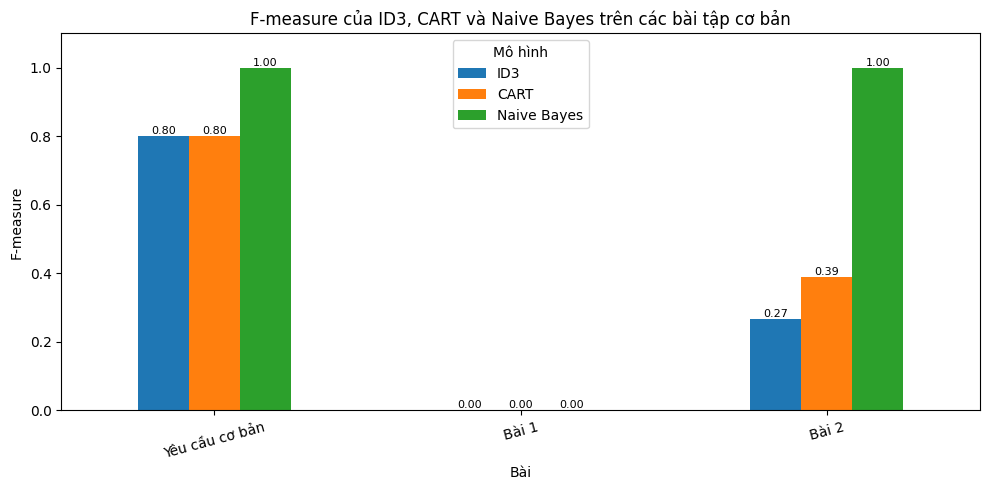

In [7]:
in_ten()
bang_f = pd.DataFrame(tong_hop)
display(bang_f.round(4))

pivot = bang_f.pivot(index="Bài", columns="Mô hình", values="F-measure")[["ID3", "CART", "Naive Bayes"]]
pivot = pivot.loc[bang_f["Bài"].unique()]
pivot.plot(kind="bar", figsize=(10, 5), rot=15)
plt.title("F-measure của ID3, CART và Naive Bayes trên các bài tập cơ bản")
plt.ylabel("F-measure")
plt.ylim(0, 1.1)
for cont in plt.gca().containers:
    plt.gca().bar_label(cont, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.show()

### Nhận xét
Điền nhận xét dựa trên bảng và biểu đồ ở trên. Gợi ý:
- Mô hình nào có F-measure cao nhất ở từng bài? Precision và Recall chênh lệch nhau thế nào (F-measure bị kéo về giá trị nhỏ hơn).
- Tập kiểm thử chỉ có 3–4 mẫu nên F-measure thay đổi rất lớn chỉ với 1 mẫu dự đoán sai → không đủ cơ sở kết luận chắc chắn mô hình nào tốt hơn.
- Ở bài cảm xúc (3 lớp), một lớp không được dự đoán đúng làm F-measure của lớp đó bằng 0 và kéo thấp trung bình macro.